# NLP Sarcasm Detection using RoBERTa with Sentiment-Incongruence Analysis

**MCA AI/ML — Continuous Assessment (CA) Project**

### Central research question

> Can contextual representations from RoBERTa improve sarcasm detection compared with a TF-IDF baseline, and can an auxiliary sentiment task provide useful additional context?

### Dataset scope used in this corrected notebook

This version intentionally uses **only two datasets**:

1. **News Headlines Sarcasm Dataset** — `Sarcasm_Headlines_Dataset_v2.json`  
   Primary dataset with human-annotated `is_sarcastic` labels.
2. **Amazon Unlocked Mobile Reviews** — `Amazon_Unlocked_Mobile.csv`  
   Used for auxiliary **rating-derived sentiment** and qualitative cross-domain analysis.

The SemEval Laptop/Restaurant datasets have been removed from the executable pipeline because they are not available in the current project folder.

### Important methodological note

Sarcasm labels come **only** from the human-annotated News Headlines dataset. Amazon star ratings are used only to derive a coarse sentiment signal for the auxiliary task:

- 1–2 stars → negative
- 3 stars → neutral
- 4–5 stars → positive

These are **rating-derived labels**, not manually annotated sentiment labels. They are therefore reported separately and are not presented as gold-standard sentiment ground truth.

### Runtime design

The notebook defaults to **FAST_MODE** so you do not have to wait for very long RoBERTa training runs. You can disable it later for a larger final experiment.


## 1. Problem Statement and Objectives

Sarcasm is difficult for NLP systems because the literal wording of a sentence can conflict with its intended meaning. For example:

> "I absolutely love waiting three hours for my food."

The word *love* is positive on the surface, while the surrounding context suggests dissatisfaction.

### Objectives

1. Study the architecture and working process of **RoBERTa**.
2. Train a supervised RoBERTa classifier for binary sarcasm detection.
3. Compare RoBERTa with a **TF-IDF + Logistic Regression** baseline.
4. Add an auxiliary sentiment head using Amazon review ratings converted into coarse sentiment classes.
5. Examine **sentiment incongruence** as a post-hoc interpretability signal rather than using it to create sarcasm labels.
6. Evaluate models using accuracy, precision, recall, macro-F1, ROC-AUC, confusion matrices, and error analysis.
7. Demonstrate predictions on custom examples and provide LIME-based explanations.


## 2. Why Sarcasm Detection?

- It is a genuinely hard NLP problem: it requires modelling context, not just word polarity.
- It has direct applications in social-media monitoring, customer-feedback analysis, and
  sentiment-analysis pipelines, where sarcastic text is a major source of misclassification.
- It is a good vehicle for demonstrating **contextual** representations (RoBERTa) versus
  **bag-of-words** representations (TF-IDF), because sarcasm detection is one of the tasks where
  the difference between the two is most visible.

**Important scoping note, stated up front and honoured throughout this notebook:**
Sentiment incongruence (positive wording + negative underlying signal) is a *useful correlate*
of sarcasm, not a definition of it. Negative sentiment is not sarcasm, and positive sentiment is
not "safely non-sarcastic" either. Sarcasm detection here is therefore treated strictly as a
**supervised classification task trained on real, human-annotated sarcasm labels**; sentiment
incongruence is only ever used as a downstream *analysis/interpretability* signal, never as a
source of training or evaluation labels.


## 3. Why RoBERTa?

RoBERTa ("Robustly Optimized BERT Pretraining Approach") is a transformer encoder pre-trained
with masked-language-modelling on a very large text corpus, using the same architecture as BERT
but with training-procedure changes (no next-sentence-prediction task, larger batches, more
data, dynamic masking) that make it a stronger starting point for fine-tuning.

Why it fits this task better than TF-IDF or a plain RNN/LSTM:

| Property | TF-IDF + LogReg | LSTM (from scratch) | RoBERTa (pre-trained) |
|---|---|---|---|
| Uses word order / context | ✗ (bag of words) | ✓ (sequential) | ✓ (full self-attention) |
| Pre-trained language knowledge | ✗ | ✗ | ✓ (large corpus) |
| Handles long-range dependencies | ✗ | partially (vanishing gradient) | ✓ |
| Needs large labelled data to work well | mostly, still limited ceiling | yes, a lot | less — fine-tuning transfers prior knowledge |
| Captures subword / rare-word info | partial (n-grams) | limited | ✓ (byte-level BPE) |

Sarcasm detection depends on **how words relate to each other in context**
(e.g. "great" next to "waiting three hours" is what signals sarcasm — neither word alone does),
which is exactly what self-attention is designed to model.


## 5. Architecture Overview

```text
                 ┌─────────────────────────────────────┐
                 │             DATA SOURCES             │
                 │                                      │
                 │ News Headlines       Amazon Reviews  │
                 │ sarcasm labels       rating signal   │
                 └──────────────────┬───────────────────┘
                                    │
                                    ▼
                           Text Preprocessing
                      (URLs, mentions, whitespace)
                                    │
                                    ▼
                           RoBERTa Tokenizer
                             (BPE tokens)
                                    │
                                    ▼
                         RoBERTa-base Encoder
                          (shared contextual
                           representation)
                           ┌────────┴────────┐
                           ▼                 ▼
                    Sarcasm Head       Sentiment Head
                    2 classes           3 classes
                    supervised          rating-derived
                           │                 │
                           └────────┬────────┘
                                    ▼
                       Sentiment-Incongruence
                         Post-hoc Analysis
                                    │
                                    ▼
                         Evaluation + LIME
                                    │
                                    ▼
                         Custom Text Demo
```

### Models

| Model | Purpose | Training signal |
|---|---|---|
| Model 1 | TF-IDF + Logistic Regression baseline | Human sarcasm labels |
| Model 2 | Standard RoBERTa | Human sarcasm labels |
| Model 3 | Multi-Task RoBERTa | Sarcasm + rating-derived sentiment |
| Focal ablation | Optional only | Disabled by default for runtime |

The primary claim of the project remains **supervised sarcasm detection**. Sentiment incongruence is an analysis signal, not the source of sarcasm ground truth.


## 6. Dataset Description

| Dataset | Size in this project | Main fields | Role |
|---|---:|---|---|
| News Headlines Sarcasm Dataset | 28,619 | `is_sarcastic`, `headline`, `article_link` | **Primary sarcasm dataset** |
| Amazon Unlocked Mobile Reviews | 413,840 | `Reviews`, `Rating`, plus product metadata | **Auxiliary sentiment + qualitative domain analysis** |

### News Headlines Sarcasm Dataset

The file `Sarcasm_Headlines_Dataset_v2.json` contains news headlines with the binary `is_sarcastic` label. This is the only source of ground-truth sarcasm labels.

### Amazon Unlocked Mobile Reviews

The Amazon file contains mobile-product reviews and 1–5 star ratings. It does **not** contain sarcasm labels. We therefore do not calculate Amazon sarcasm accuracy/F1.

For the auxiliary sentiment task, ratings are converted into three coarse classes:

- `1–2` → negative
- `3` → neutral
- `4–5` → positive

This is explicitly called **rating-derived sentiment** throughout the notebook.


## 7. Install Dependencies

Run this once. Versions are loosely pinned to known-compatible ranges rather than exact
versions, since exact old pins tend to break as Kaggle/Colab base images update.


                         PROBLEM
                            │
                            ▼
                  Sarcasm Detection
                            │
                            ▼
               Traditional Baseline
              TF-IDF + Logistic Regression
                            │
                            ▼
                    Pre-trained Model
                       RoBERTa-base
                            │
                            ▼
                Standard RoBERTa Model
                            │
                            ▼
                  Proposed Improvement
                Multi-Task RoBERTa
                    /           \
                   /             \
          Sarcasm Task       Sentiment Task
               │                   │
               └────────┬──────────┘
                        ▼
                 Shared Encoder
                        │
                        ▼
                 Model Comparison
                        │
                        ▼
              Performance Evaluation
                        │
          ┌─────────────┼─────────────┐
          ▼             ▼             ▼
      F1/AUC       Confusion       ROC Curve
                    Matrix
                        │
                        ▼
              Error Analysis
                        │
                        ▼
          Sentiment-Incongruence
                 Analysis
                        │
                        ▼
                   LIME
               Explainability
                        │
                        ▼
                 Prototype Demo
                        │
                        ▼
             Strengths / Limitations
                        │
                        ▼
               Future Improvements

## Dependency Check

Run this cell once. It does **not** reinstall packages automatically, which avoids unnecessary
internet downloads and startup delays.

If something is missing, install it manually in your environment:

```bash
pip install torch transformers scikit-learn lime matplotlib seaborn pandas numpy tqdm
```

The notebook then continues with the existing environment.


## 8. Imports

In [1]:
import os, re, glob, json, random, warnings
from contextlib import nullcontext
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import RobertaTokenizerFast, RobertaModel, get_linear_schedule_with_warmup

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
)
from lime.lime_text import LimeTextExplainer

sns.set_theme(style="whitegrid", palette="muted")


def find_col(df, candidates):
    """Return the first matching column name, ignoring case/whitespace."""
    lower = {str(c).lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower().strip() in lower:
            return lower[candidate.lower().strip()]
    return None


def safe_read_csv(path):
    """Read CSV with common encoding fallbacks."""
    for enc in ["utf-8", "latin-1", "cp1252", "utf-8-sig"]:
        try:
            return pd.read_csv(path, encoding=enc, on_bad_lines="skip")
        except Exception:
            continue
    raise FileNotFoundError(f"Could not read {path} with supported encodings.")


print("Imports and helper functions loaded successfully.")


Imports and helper functions loaded successfully.


## 9. Configuration

In [11]:
def find_dataset_roots():
    """Find common local/Kaggle dataset locations."""
    roots = [
        "/kaggle/input",
        "./data",
        "../data",
        "./nlp_dataset",
        "../nlp_dataset",
        ".",
    ]
    return [r for r in roots if os.path.exists(r)]


SEARCH_ROOTS = find_dataset_roots()

print("Search roots:")
for root in SEARCH_ROOTS:
    print(f"  {root}")


_FILE_CACHE = {}


def locate_file(filename):
    """Recursively locate a dataset file and cache the result."""
    
    if filename in _FILE_CACHE:
        return _FILE_CACHE[filename]

    for root in SEARCH_ROOTS:
        matches = glob.glob(
            os.path.join(root, "**", filename),
            recursive=True
        )

        if matches:
            _FILE_CACHE[filename] = matches[0]
            return matches[0]

    _FILE_CACHE[filename] = None
    return None


class Config:

    # ============================================================
    # Reproducibility
    # ============================================================
    SEED = 42

    # ============================================================
    # Model
    # ============================================================
    MODEL_NAME = "roberta-base"

    # ============================================================
    # Dataset / Runtime
    # ============================================================
    FAST_MODE = True

    # Used to keep the first experiment reasonably fast
    MAX_SARC_TRAIN = 6000
    MAX_AMAZON_SENTIMENT = 6000

    # Set to False later if you want to use the full datasets
    USE_FULL_DATA = False

    # ============================================================
    # Tokenization
    # ============================================================
    MAX_LEN = 96

    # ============================================================
    # Training
    # ============================================================
    BATCH_SIZE = 32
    EPOCHS = 2

    LR = 2e-5
    WEIGHT_DECAY = 0.01
    WARMUP_RATIO = 0.10
    DROPOUT = 0.15
    MAX_GRAD_NORM = 1.0

    # ============================================================
    # Multi-task loss weights
    # ============================================================
    ALPHA_SARCASM = 0.70
    BETA_SENTIMENT = 0.30

    # ============================================================
    # Focal Loss
    # ============================================================
    # Disabled by default because your first goal is to get
    # the complete pipeline working quickly.
    RUN_FOCAL_LOSS_ABLATION = False
    FOCAL_GAMMA = 2.0

    # ============================================================
    # Labels
    # ============================================================
    SARCASM_ID2LABEL = {
        0: "not_sarcastic",
        1: "sarcastic"
    }

    SENTIMENT_ID2LABEL = {
        0: "negative",
        1: "neutral",
        2: "positive"
    }

    # ============================================================
    # Output
    # ============================================================
    OUTPUT_DIR = "./sarcasm_outputs"

    # ============================================================
    # Device
    # ============================================================
    DEVICE = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )


CFG = Config()

os.makedirs(
    CFG.OUTPUT_DIR,
    exist_ok=True
)


def set_seed(seed=42):
    """Make experiments reproducible."""
    
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG.SEED)


# Improve matrix multiplication performance on modern GPUs
if CFG.DEVICE.type == "cuda":
    torch.set_float32_matmul_precision("high")


print("=" * 60)
print("CONFIGURATION")
print("=" * 60)

print(f"Device       : {CFG.DEVICE}")
print(f"Model        : {CFG.MODEL_NAME}")
print(f"Seed         : {CFG.SEED}")
print(f"Fast mode    : {CFG.FAST_MODE}")
print(f"Full data    : {CFG.USE_FULL_DATA}")
print(f"Batch size   : {CFG.BATCH_SIZE}")
print(f"Epochs       : {CFG.EPOCHS}")
print(f"Max length   : {CFG.MAX_LEN}")
print(f"Learning rate: {CFG.LR}")
print(f"Output dir   : {CFG.OUTPUT_DIR}")

print("=" * 60)

Search roots:
  .
CONFIGURATION
Device       : cpu
Model        : roberta-base
Seed         : 42
Fast mode    : True
Full data    : False
Batch size   : 32
Epochs       : 2
Max length   : 96
Learning rate: 2e-05
Output dir   : ./sarcasm_outputs


## 10. Load Datasets

In [12]:
# ============================================================
# 1. Main sarcasm dataset
# ============================================================

print("=" * 70)
print("1. Loading Main Sarcasm Dataset")
print("=" * 70)

_headlines_path = locate_file("Sarcasm_Headlines_Dataset_v2.json")

if _headlines_path is None:
    raise FileNotFoundError(
        "Sarcasm_Headlines_Dataset_v2.json not found. "
        "Place it in the project folder/data folder or attach it on Kaggle."
    )

headlines_raw = pd.read_json(_headlines_path, lines=True)

print("Dataset loaded successfully!")
print(f"Rows       : {len(headlines_raw):,}")
print(f"Columns    : {list(headlines_raw.columns)}")
print(f"File path  : {_headlines_path}")


# ============================================================
# 2. Amazon reviews dataset
# ============================================================

print("\n" + "=" * 70)
print("2. Loading Amazon Reviews Dataset")
print("=" * 70)

_amazon_path = locate_file("Amazon_Unlocked_Mobile.csv")

if _amazon_path is None:
    raise FileNotFoundError(
        "Amazon_Unlocked_Mobile.csv not found. "
        "Place it in the project folder/data folder or attach it on Kaggle."
    )

amazon_raw = safe_read_csv(_amazon_path)

print("Dataset loaded successfully!")
print(f"Rows       : {len(amazon_raw):,}")
print(f"Columns    : {list(amazon_raw.columns)}")
print(f"File path  : {_amazon_path}")


# ============================================================
# Final summary
# ============================================================

print("\n" + "=" * 70)
print("DATASET LOADING SUMMARY")
print("=" * 70)
print(f"Main sarcasm dataset : {len(headlines_raw):,} rows")
print(f"Amazon dataset       : {len(amazon_raw):,} rows")
print("SemEval ABSA         : NOT USED in this version")
print("=" * 70)


1. Loading Main Sarcasm Dataset
Dataset loaded successfully!
Rows       : 28,619
Columns    : ['is_sarcastic', 'headline', 'article_link']
File path  : .\Sarcasm_Headlines_Dataset_v2.json

2. Loading Amazon Reviews Dataset
Dataset loaded successfully!
Rows       : 413,840
Columns    : ['Product Name', 'Brand Name', 'Price', 'Rating', 'Reviews', 'Review Votes']
File path  : .\Amazon_Unlocked_Mobile.csv

DATASET LOADING SUMMARY
Main sarcasm dataset : 28,619 rows
Amazon dataset       : 413,840 rows
SemEval ABSA         : NOT USED in this version


## 11. Dataset Exploration

In [13]:
print("News Headlines Sarcasm Dataset — columns:")
print(list(headlines_raw.columns))
display(headlines_raw.head())

print("\nAmazon Reviews Dataset — columns:")
print(list(amazon_raw.columns))
display(amazon_raw.head())

print("\nMissing values:")
display(pd.DataFrame({
    "news_headlines": headlines_raw.isna().sum(),
    "amazon_reviews": amazon_raw.isna().sum()
}).fillna(0))


News Headlines Sarcasm Dataset — columns:
['is_sarcastic', 'headline', 'article_link']


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...



Amazon Reviews Dataset — columns:
['Product Name', 'Brand Name', 'Price', 'Rating', 'Reviews', 'Review Votes']


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0



Missing values:


,news_headlines,amazon_reviews
Brand Name,0.0,65171.0
Price,0.0,5933.0
Product Name,0.0,0.0
Rating,0.0,0.0
Review Votes,0.0,12296.0
Reviews,0.0,70.0
article_link,0.0,0.0
headline,0.0,0.0
is_sarcastic,0.0,0.0


## 12. Class Distribution

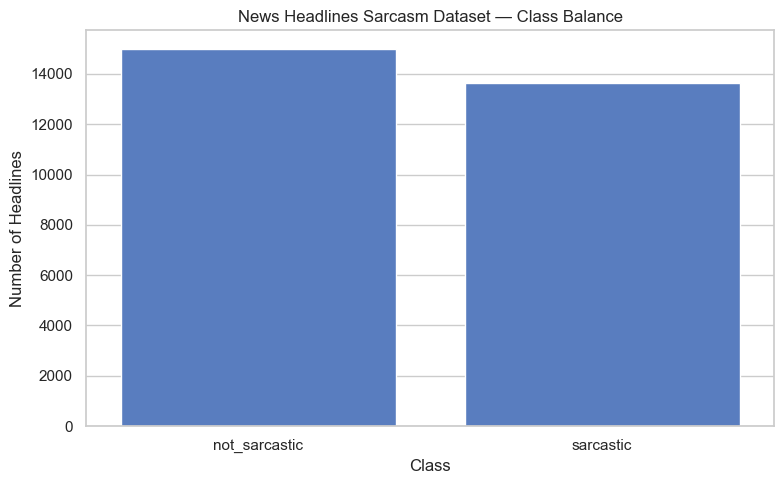

In [14]:
# ============================================================
# Class Distribution — Main Sarcasm Dataset
# ============================================================

plt.figure(figsize=(8, 5))

sarcasm_labels = headlines_raw["is_sarcastic"].map({
    0: "not_sarcastic",
    1: "sarcastic"
})

sns.countplot(
    x=sarcasm_labels,
    order=["not_sarcastic", "sarcastic"]
)

plt.title("News Headlines Sarcasm Dataset — Class Balance")
plt.xlabel("Class")
plt.ylabel("Number of Headlines")
plt.tight_layout()

plt.savefig(
    f"{CFG.OUTPUT_DIR}/sarcasm_class_distribution.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

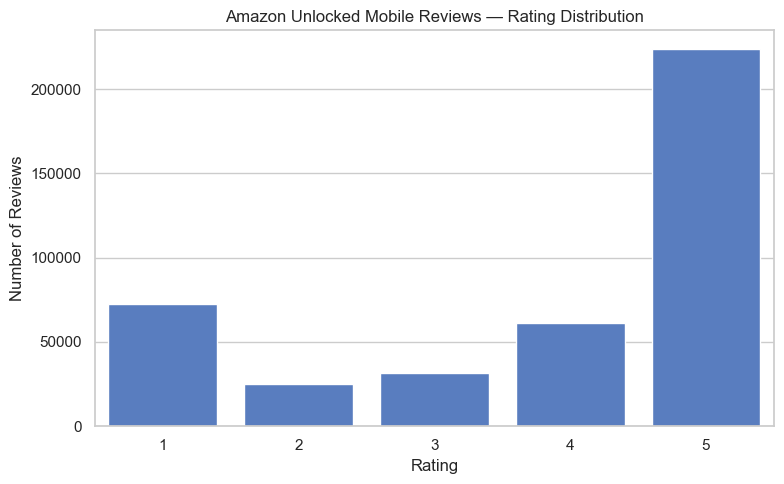

In [15]:
# ============================================================
# Amazon Dataset — Rating Distribution
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    x=amazon_raw["Rating"].dropna().astype(int)
)

plt.title("Amazon Unlocked Mobile Reviews — Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    f"{CFG.OUTPUT_DIR}/amazon_rating_distribution.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

In [16]:
print("Main Sarcasm Dataset:")
display(headlines_raw.head())

print("\nAmazon Reviews Dataset:")
display(amazon_raw[["Reviews", "Rating"]].head())


Main Sarcasm Dataset:


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...



Amazon Reviews Dataset:


,Reviews,Rating
0,I feel so LUCKY to have found this used (phone...,5
1,"nice phone, nice up grade from my pantach revu...",4
2,Very pleased,5
3,It works good but it goes slow sometimes but i...,4
4,Great phone to replace my lost phone. The only...,4


## 13. Data Cleaning

Cleaning is kept **conservative** on purpose. Sarcasm signals often live in exactly the things a
"thorough" cleaner would strip out — punctuation emphasis, capitalisation, repeated exclamation
marks, emoji, hashtags used as commentary (e.g. *"Great!!! Another update broke everything 🙄"*).
So this pipeline only:
- replaces URLs and @mentions with placeholder tokens,
- unwraps hashtags into plain words (`#neveragain` → `neveragain`) without deleting them,
- decodes HTML entities,
- normalises whitespace.

It does **not** lowercase, strip punctuation, remove stopwords, or remove emoji.


In [17]:
def clean_text(text):
    """Conservative text cleaning; preserve wording important for sarcasm."""
    t = str(text)
    t = re.sub(r"http\S+|www\.\S+", "[URL]", t)
    t = re.sub(r"@\w+", "[USER]", t)
    t = re.sub(r"#(\w+)", r"\1", t)
    t = t.replace("&amp;", "&").replace("&lt;", "<").replace("&gt;", ">")
    t = re.sub(r"\s+", " ", t).strip()
    return t


headlines = (
    headlines_raw
    .rename(columns={"is_sarcastic": "sarcasm", "headline": "text"})
    [["text", "sarcasm"]]
    .copy()
)

headlines["text"] = headlines["text"].apply(clean_text)
headlines = (
    headlines[headlines["text"].str.len() > 3]
    .dropna()
    .drop_duplicates(subset=["text"])
    .reset_index(drop=True)
)

print(f"Clean sarcasm dataset: {len(headlines):,} rows")
print("Class distribution:")
print(headlines["sarcasm"].value_counts().sort_index())
display(headlines.sample(3, random_state=CFG.SEED))


Clean sarcasm dataset: 28,503 rows
Class distribution:
sarcasm
0    14951
1    13552
Name: count, dtype: int64


,text,sarcasm
24106,marco rubio nabs his first 2016 win in minneso...,0
6020,oops: hot mic broadcasts al roker going to the...,0
20292,white house pretty sure uzbekistan diplomat st...,1


## 14. Leakage-Free Train / Validation / Test Split

**This is the main correctness fix in this notebook.** An earlier version built train/validation
data from the full sarcasm dataset, and then separately built a "held-out test" set again from
the *same* full dataset — with no check that the same headline didn't land in both. Reported
test numbers from that version (~97.7% accuracy / ~97.7% macro-F1) are therefore not trustworthy
as an independent-test result and are **not repeated in this notebook**.

The function below:
1. drops exact-duplicate texts *before* splitting,
2. does a single stratified 70/15/15 split (train/val/test),
3. asserts there is zero text overlap between the three resulting sets.

The assertion is not decorative — if it fails, the split code is wrong and the notebook stops
rather than silently reporting leaked numbers.


In [18]:
def clean_stratified_split(
    df, text_col, label_col,
    train_size=0.70, val_size=0.15, test_size=0.15, seed=42
):
    """Create a leakage-free stratified train/validation/test split."""
    assert abs(train_size + val_size + test_size - 1.0) < 1e-6

    train_df, temp_df = train_test_split(
        df,
        train_size=train_size,
        random_state=seed,
        stratify=df[label_col]
    )

    rel_val = val_size / (val_size + test_size)

    val_df, test_df = train_test_split(
        temp_df,
        train_size=rel_val,
        random_state=seed,
        stratify=temp_df[label_col]
    )

    tr = set(train_df[text_col])
    va = set(val_df[text_col])
    te = set(test_df[text_col])

    assert not (tr & va)
    assert not (tr & te)
    assert not (va & te)

    print(
        f"Full split -> train={len(train_df):,}, "
        f"val={len(val_df):,}, test={len(test_df):,}"
    )
    print("Text overlap check: PASSED")

    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True),
        test_df.reset_index(drop=True)
    )


print("Splitting the News Headlines Sarcasm Dataset:")
sarc_train_full, sarc_val, sarc_test = clean_stratified_split(
    headlines,
    text_col="text",
    label_col="sarcasm",
    seed=CFG.SEED
)

# Keep validation/test fixed so model comparisons are fair.
# FAST_MODE only limits the training subset.
if CFG.FAST_MODE and len(sarc_train_full) > CFG.MAX_SARC_TRAIN:
    sarc_train, _ = train_test_split(
        sarc_train_full,
        train_size=CFG.MAX_SARC_TRAIN,
        random_state=CFG.SEED,
        stratify=sarc_train_full["sarcasm"]
    )
    sarc_train = sarc_train.reset_index(drop=True)
    print(
        f"\nFAST_MODE: using {len(sarc_train):,} of "
        f"{len(sarc_train_full):,} sarcasm training rows."
    )
else:
    sarc_train = sarc_train_full.copy()

print(f"\nFinal training rows used : {len(sarc_train):,}")
print(f"Validation rows           : {len(sarc_val):,}")
print(f"Test rows                 : {len(sarc_test):,}")
print(f"Train sarcasm rate        : {sarc_train['sarcasm'].mean():.3f}")
print(f"Validation sarcasm rate   : {sarc_val['sarcasm'].mean():.3f}")
print(f"Test sarcasm rate         : {sarc_test['sarcasm'].mean():.3f}")


Splitting the News Headlines Sarcasm Dataset:
Full split -> train=19,952, val=4,275, test=4,276
Text overlap check: PASSED

FAST_MODE: using 6,000 of 19,952 sarcasm training rows.

Final training rows used : 6,000
Validation rows           : 4,275
Test rows                 : 4,276
Train sarcasm rate        : 0.475
Validation sarcasm rate   : 0.476
Test sarcasm rate         : 0.475


### Auxiliary sentiment task — Amazon rating-derived labels

Amazon does not contain a human-annotated sentiment column. To support the multi-task architecture,
we derive a **coarse sentiment label from the star rating**:

| Rating | Derived sentiment |
|---|---|
| 1–2 | negative |
| 3 | neutral |
| 4–5 | positive |

This is a weak/rating-derived supervision signal. It is useful for demonstrating the multi-task
architecture, but it must not be described as equivalent to manually annotated sentiment.

The Amazon sentiment data is sampled for runtime efficiency and split into train/validation sets.
It is **not used to create sarcasm labels**.


In [19]:
# ============================================================
# Amazon rating-derived sentiment dataset
# ============================================================

amazon_sent = amazon_raw[["Reviews", "Rating"]].copy()
amazon_sent["Rating"] = pd.to_numeric(amazon_sent["Rating"], errors="coerce")
amazon_sent["text"] = amazon_sent["Reviews"].astype(str).apply(clean_text)

amazon_sent = amazon_sent.dropna(subset=["Rating", "text"])
amazon_sent = amazon_sent[amazon_sent["text"].str.len() > 3]
amazon_sent = amazon_sent[amazon_sent["Rating"].between(1, 5)]
amazon_sent = amazon_sent.drop_duplicates(subset=["text"]).reset_index(drop=True)

def rating_to_sentiment(rating):
    if rating <= 2:
        return 0
    elif rating == 3:
        return 1
    return 2

amazon_sent["sentiment"] = amazon_sent["Rating"].apply(rating_to_sentiment)

# Sample a manageable, stratified subset for the auxiliary task.
if CFG.FAST_MODE and len(amazon_sent) > CFG.MAX_AMAZON_SENTIMENT:
    amazon_sent, _ = train_test_split(
        amazon_sent,
        train_size=CFG.MAX_AMAZON_SENTIMENT,
        random_state=CFG.SEED,
        stratify=amazon_sent["sentiment"]
    )
    amazon_sent = amazon_sent.reset_index(drop=True)

sent_train, sent_val = train_test_split(
    amazon_sent,
    test_size=0.15,
    random_state=CFG.SEED,
    stratify=amazon_sent["sentiment"]
)

sent_train = sent_train.reset_index(drop=True)
sent_val = sent_val.reset_index(drop=True)

print("=" * 60)
print("AMAZON RATING-DERIVED SENTIMENT")
print("=" * 60)
print(f"Rows used       : {len(amazon_sent):,}")
print(f"Train rows      : {len(sent_train):,}")
print(f"Validation rows : {len(sent_val):,}")
print("\nClass distribution:")
print(
    amazon_sent["sentiment"]
    .map(CFG.SENTIMENT_ID2LABEL)
    .value_counts()
)
print("\nNOTE: These are derived from star ratings, not human sentiment annotations.")


AMAZON RATING-DERIVED SENTIMENT
Rows used       : 6,000
Train rows      : 5,100
Validation rows : 900

Class distribution:
sentiment
positive    3831
negative    1638
neutral      531
Name: count, dtype: int64

NOTE: These are derived from star ratings, not human sentiment annotations.


## 15. Tokenization

RoBERTa uses **byte-level Byte-Pair Encoding (BPE)**: text is first mapped to bytes, then merged
greedily into subword units learned from RoBERTa's pretraining corpus. This means:

- rare or unseen words are still represented (as a sequence of familiar subwords) instead of
  becoming a single `[UNK]` token, unlike a fixed word-level vocabulary,
- the vocabulary stays a manageable size (~50k tokens) while still covering effectively any
  English text.

```
Raw text  ->  Byte-level BPE subword tokens  ->  input IDs  ->  attention mask  ->  RoBERTa
```

`input_ids` are the integer indices of each subword in RoBERTa's vocabulary; `attention_mask` is
a 0/1 mask telling the model which positions are real tokens versus padding.


In [20]:
tokenizer = RobertaTokenizerFast.from_pretrained(CFG.MODEL_NAME)

example = "Great, another update that broke everything."
enc = tokenizer(example, return_tensors="pt")
print("Text        :", example)
print("Tokens      :", tokenizer.convert_ids_to_tokens(enc["input_ids"][0]))
print("input_ids   :", enc["input_ids"][0].tolist())
print("attn_mask   :", enc["attention_mask"][0].tolist())
print(f"\nVocab size  : {tokenizer.vocab_size:,}")


Text        : Great, another update that broke everything.
Tokens      : ['<s>', 'Great', ',', 'Ġanother', 'Ġupdate', 'Ġthat', 'Ġbroke', 'Ġeverything', '.', '</s>']
input_ids   : [0, 19065, 6, 277, 2935, 14, 2263, 960, 4, 2]
attn_mask   : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Vocab size  : 50,265


## 16. PyTorch Dataset & DataLoaders

A single generic `TextDataset` class is reused for both tasks (sarcasm and sentiment) — it just
needs a list of texts and a list of integer labels. Two independent DataLoaders are built per
task (train/val/test for sarcasm; train/val/test for sentiment).

`WeightedRandomSampler`/oversampling from the earlier version is **not used** here: the main
sarcasm dataset is close to balanced (~47.5% / 52.5%), so oversampling would add complexity
without a clear benefit. Plain `shuffle=True` is used instead. If a real class imbalance shows up
in Section 20 (Focal Loss ablation), that is examined directly rather than assumed upfront.


In [21]:
# ============================================================
# PyTorch Dataset & DataLoaders
# ============================================================

class TextDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tok = tok
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tok(
            self.texts[idx],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }


# ---------------- Sarcasm loaders ----------------

ds_sarc_train = TextDataset(
    sarc_train["text"], sarc_train["sarcasm"], tokenizer, CFG.MAX_LEN
)
ds_sarc_val = TextDataset(
    sarc_val["text"], sarc_val["sarcasm"], tokenizer, CFG.MAX_LEN
)
ds_sarc_test = TextDataset(
    sarc_test["text"], sarc_test["sarcasm"], tokenizer, CFG.MAX_LEN
)

dl_sarc_train = DataLoader(
    ds_sarc_train, batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=0
)
dl_sarc_val = DataLoader(
    ds_sarc_val, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=0
)
dl_sarc_test = DataLoader(
    ds_sarc_test, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=0
)


# ---------------- Amazon sentiment loaders ----------------

ds_sent_train = TextDataset(
    sent_train["text"], sent_train["sentiment"], tokenizer, CFG.MAX_LEN
)
ds_sent_val = TextDataset(
    sent_val["text"], sent_val["sentiment"], tokenizer, CFG.MAX_LEN
)

dl_sent_train = DataLoader(
    ds_sent_train, batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=0
)
dl_sent_val = DataLoader(
    ds_sent_val, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=0
)


print("=" * 60)
print("DATA LOADERS")
print("=" * 60)
print(
    f"Sarcasm  -> train={len(ds_sarc_train):,}, "
    f"val={len(ds_sarc_val):,}, test={len(ds_sarc_test):,}"
)
print(
    f"Sentiment -> train={len(ds_sent_train):,}, "
    f"val={len(ds_sent_val):,}"
)
print(f"Sarcasm training batches: {len(dl_sarc_train):,}")
print(f"Sentiment training batches: {len(dl_sent_train):,}")
print("=" * 60)


DATA LOADERS
Sarcasm  -> train=6,000, val=4,275, test=4,276
Sentiment -> train=5,100, val=900
Sarcasm training batches: 188
Sentiment training batches: 160


## 17. Model 1 — TF-IDF + Logistic Regression Baseline

```
Text -> TF-IDF (unigrams+bigrams) -> Logistic Regression -> Sarcasm prediction
```

This is a bag-of-words baseline: it has no notion of word order or context beyond adjacent-word
bigrams. It is fast to train and a fair, standard point of comparison for the transformer models.


In [22]:
baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "clf",
        LogisticRegression(
            max_iter=300,
            class_weight="balanced",
            random_state=CFG.SEED
        )
    ),
])

baseline.fit(
    sarc_train["text"],
    sarc_train["sarcasm"]
)

base_pred = baseline.predict(sarc_test["text"])
base_prob = baseline.predict_proba(sarc_test["text"])[:, 1]

print("Model 1 (TF-IDF + Logistic Regression) trained.")


Model 1 (TF-IDF + Logistic Regression) trained.


### Shared evaluation helper (used by every sarcasm model below)

In [23]:
def compute_binary_metrics(y_true, y_pred, y_prob_pos):
    acc = accuracy_score(y_true, y_pred)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(y_true, y_prob_pos)
    except ValueError:
        auc = float("nan")
    return {
        "accuracy": acc, "precision_macro": p_m, "recall_macro": r_m, "macro_f1": f1_m,
        "weighted_f1": f1_w, "roc_auc": auc,
    }

base_pred = baseline.predict(sarc_test["text"])
base_prob = baseline.predict_proba(sarc_test["text"])[:, 1]
metrics_model1 = compute_binary_metrics(sarc_test["sarcasm"], base_pred, base_prob)
print("Model 1 (TF-IDF+LogReg) test metrics:")
for k, v in metrics_model1.items():
    print(f"  {k:<16}: {v:.4f}")
print()
print(classification_report(sarc_test["sarcasm"], base_pred,
                             target_names=["not_sarcastic", "sarcastic"], zero_division=0))


Model 1 (TF-IDF+LogReg) test metrics:
  accuracy        : 0.8113
  precision_macro : 0.8118
  recall_macro    : 0.8124
  macro_f1        : 0.8112
  weighted_f1     : 0.8114
  roc_auc         : 0.8914

               precision    recall  f1-score   support

not_sarcastic       0.84      0.79      0.81      2243
    sarcastic       0.78      0.84      0.81      2033

     accuracy                           0.81      4276
    macro avg       0.81      0.81      0.81      4276
 weighted avg       0.81      0.81      0.81      4276



## 18. Model 2 — Standard RoBERTa Sarcasm Classifier

```
Input text -> RoBERTa tokenizer -> RoBERTa-base encoder (12 layers, hidden=768, ~125M params)
           -> [CLS] contextual representation -> classification head -> {sarcastic, not_sarcastic}
```

The `[CLS]` token's final hidden state is used as a pooled sentence representation (RoBERTa
computes it via self-attention over the *entire* sequence, so it already encodes context from
every other token, unlike a bag-of-words vector). The head on top is a small MLP:

```
[CLS] (768) -> Dropout -> Linear(768→256) -> GELU -> Dropout -> Linear(256→2)
```

This model is single-task: it only has a sarcasm head, and is fine-tuned only on the sarcasm
training set.


In [24]:
class RobertaSarcasmClassifier(nn.Module):
    '''Standard single-task RoBERTa sarcasm classifier (Model 2).'''
    def __init__(self, model_name=CFG.MODEL_NAME, hidden_size=768, dropout=CFG.DROPOUT, n_classes=2):
        super().__init__()
        self.encoder = RobertaModel.from_pretrained(model_name)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_classes),
        )

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.head(cls)

print("RobertaSarcasmClassifier defined.")


RobertaSarcasmClassifier defined.


## 19. Model 3 — Multi-Task RoBERTa (Sarcasm + Sentiment, shared encoder)

```
                     RoBERTa-base Encoder (shared)
                                |
                       [CLS] representation
                     +----------+----------+
                     |                     |
              Sarcasm Head           Sentiment Head
           (768→256→GELU→2)       (768→256→GELU→3)
                     |                     |
          {sarcastic, not_sarcastic}  {negative, neutral, positive}
```

Both heads read the *same* shared `[CLS]` representation from one RoBERTa encoder. The idea
being tested is whether forcing the encoder to also be useful for ordinary sentiment
classification produces a representation that is *also* better for sarcasm detection (since
sarcasm partly depends on sentiment-related signal) — this is exactly the empirical question the
Model 2 vs Model 3 comparison in Section 27 is designed to answer.

Total loss during training: **L = 0.70 · L_sarcasm + 0.30 · L_sentiment**, with the sarcasm task
weighted higher since it is the primary task and the sentiment task is auxiliary.


In [25]:
class MultiTaskRoberta(nn.Module):
    '''Shared RoBERTa encoder with two independent heads (Model 3).'''
    def __init__(self, model_name=CFG.MODEL_NAME, hidden_size=768, dropout=CFG.DROPOUT,
                 n_sarcasm=2, n_sentiment=3):
        super().__init__()
        self.encoder = RobertaModel.from_pretrained(model_name)
        self.sarcasm_head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_sarcasm),
        )
        self.sentiment_head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_sentiment),
        )

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.sarcasm_head(cls), self.sentiment_head(cls), cls


class FocalLoss(nn.Module):
    '''Used only for the Section 21 ablation (Model 4), not for Models 2/3.'''
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma = gamma
        self.weight = weight

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

print("MultiTaskRoberta and FocalLoss defined.")


MultiTaskRoberta and FocalLoss defined.


## 20. Training

Two training-loop functions are defined:

- `train_single_task()` — trains a sarcasm-only model (used for **Model 2**, CrossEntropyLoss,
  and **Model 4**, the Focal-Loss ablation).
- `train_multitask()` — trains the shared-encoder model (**Model 3**) by cycling through the
  sarcasm and sentiment DataLoaders together each step and combining their losses
  (`0.7·L_sarcasm + 0.3·L_sentiment`). Because the sentiment loader is shorter, it is restarted
  (cycled) whenever it runs out, so every sarcasm batch still gets paired with a sentiment batch.

Both loops track per-epoch train loss, validation loss, and validation macro-F1 (on the sarcasm
task) so that training curves can be plotted in Section 26, and both save the checkpoint with the
best validation macro-F1.


In [26]:
def make_optimizer_and_scheduler(model, train_loader_len, epochs=CFG.EPOCHS):
    opt = AdamW(
        model.parameters(),
        lr=CFG.LR,
        weight_decay=CFG.WEIGHT_DECAY
    )
    total_steps = max(1, train_loader_len * epochs)
    warmup_steps = int(CFG.WARMUP_RATIO * total_steps)

    sched = get_linear_schedule_with_warmup(
        opt,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )
    return opt, sched


def amp_context(device):
    """Use mixed precision on CUDA; otherwise use a no-op context."""
    if device.type == "cuda":
        return torch.cuda.amp.autocast(dtype=torch.float16)
    return nullcontext()


@torch.no_grad()
def evaluate_sarcasm_head(model, loader, device, is_multitask):
    model.eval()
    all_logits, all_labels = [], []

    for batch in loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        y = batch["label"]

        with amp_context(device):
            if is_multitask:
                logits, _, _ = model(ids, mask)
            else:
                logits = model(ids, mask)

        all_logits.append(logits.float().cpu())
        all_labels.append(y)

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy()

    probs = F.softmax(logits, dim=1).numpy()
    preds = probs.argmax(1)

    loss = F.cross_entropy(logits, torch.tensor(labels)).item()
    metrics = compute_binary_metrics(labels, preds, probs[:, 1])
    metrics["loss"] = loss

    return metrics, preds, probs, labels


def train_single_task(
    model, train_loader, val_loader, device,
    epochs=CFG.EPOCHS, loss_fn=None,
    ckpt_path="model.pt", tag="Model"
):
    if loss_fn is None:
        loss_fn = nn.CrossEntropyLoss()

    opt, sched = make_optimizer_and_scheduler(
        model, len(train_loader), epochs
    )

    use_amp = device.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_macro_f1": []
    }

    best_f1 = -1.0
    model.to(device)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0

        progress = tqdm(
            train_loader,
            desc=f"[{tag}] epoch {epoch}/{epochs}"
        )

        for batch in progress:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            y = batch["label"].to(device)

            opt.zero_grad(set_to_none=True)

            with amp_context(device):
                logits = model(ids, mask)
                loss = loss_fn(logits, y)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), CFG.MAX_GRAD_NORM
            )
            scaler.step(opt)
            scaler.update()
            sched.step()

            running += loss.item()
            progress.set_postfix(loss=f"{loss.item():.3f}")

        train_loss = running / len(train_loader)

        val_metrics, *_ = evaluate_sarcasm_head(
            model, val_loader, device, is_multitask=False
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        print(
            f"[{tag}] epoch {epoch}: "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_metrics['loss']:.4f} | "
            f"val_macro_f1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save(model.state_dict(), ckpt_path)

    model.load_state_dict(
        torch.load(ckpt_path, map_location=device)
    )
    return model, history


def train_multitask(
    model, sarc_train_loader, sent_train_loader,
    sarc_val_loader, device,
    epochs=CFG.EPOCHS,
    alpha=CFG.ALPHA_SARCASM,
    beta=CFG.BETA_SENTIMENT,
    ckpt_path="model.pt",
    tag="Model3"
):
    opt, sched = make_optimizer_and_scheduler(
        model, len(sarc_train_loader), epochs
    )

    use_amp = device.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_macro_f1": []
    }

    best_f1 = -1.0
    model.to(device)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0

        sent_iter = iter(sent_train_loader)

        progress = tqdm(
            sarc_train_loader,
            desc=f"[{tag}] epoch {epoch}/{epochs}"
        )

        for sbatch in progress:
            try:
                abatch = next(sent_iter)
            except StopIteration:
                sent_iter = iter(sent_train_loader)
                abatch = next(sent_iter)

            ids = sbatch["input_ids"].to(device)
            mask = sbatch["attention_mask"].to(device)
            y_sarc = sbatch["label"].to(device)

            a_ids = abatch["input_ids"].to(device)
            a_mask = abatch["attention_mask"].to(device)
            y_sent = abatch["label"].to(device)

            opt.zero_grad(set_to_none=True)

            with amp_context(device):
                sarc_logits, _, _ = model(ids, mask)
                _, sent_logits, _ = model(a_ids, a_mask)

                loss_sarc = F.cross_entropy(sarc_logits, y_sarc)
                loss_sent = F.cross_entropy(sent_logits, y_sent)

                loss = alpha * loss_sarc + beta * loss_sent

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), CFG.MAX_GRAD_NORM
            )
            scaler.step(opt)
            scaler.update()
            sched.step()

            running += loss.item()
            progress.set_postfix(loss=f"{loss.item():.3f}")

        train_loss = running / len(sarc_train_loader)

        val_metrics, *_ = evaluate_sarcasm_head(
            model, sarc_val_loader, device, is_multitask=True
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        print(
            f"[{tag}] epoch {epoch}: "
            f"joint_loss={train_loss:.4f} | "
            f"val_sarcasm_loss={val_metrics['loss']:.4f} | "
            f"val_macro_f1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save(model.state_dict(), ckpt_path)

    model.load_state_dict(
        torch.load(ckpt_path, map_location=device)
    )
    return model, history


print("Training functions defined.")


Training functions defined.


### Train Model 2 (standard RoBERTa, CrossEntropyLoss)

In [27]:
set_seed(CFG.SEED)

model2 = RobertaSarcasmClassifier()

model2, history2 = train_single_task(
    model2,
    dl_sarc_train,
    dl_sarc_val,
    CFG.DEVICE,
    epochs=CFG.EPOCHS,
    loss_fn=nn.CrossEntropyLoss(),
    ckpt_path=f"{CFG.OUTPUT_DIR}/model2_roberta.pt",
    tag="Model2-RoBERTa"
)


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[Model2-RoBERTa] epoch 1/2:   0%|          | 0/188 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Train Model 3 (multi-task RoBERTa, shared encoder)

In [36]:
set_seed(CFG.SEED)

model3 = MultiTaskRoberta()

model3, history3 = train_multitask(
    model3,
    dl_sarc_train,
    dl_sent_train,
    dl_sarc_val,
    CFG.DEVICE,
    epochs=CFG.EPOCHS,
    ckpt_path=f"{CFG.OUTPUT_DIR}/model3_multitask.pt",
    tag="Model3-MultiTask"
)


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


NameError: name 'dl_sent_train' is not defined

### Train Model 4 — RoBERTa + Focal Loss (ablation, optional)

This ablation directly tests whether Focal Loss (designed for *hard, heavily imbalanced*
classification problems) actually helps on this dataset, given that the main sarcasm dataset is
already close to balanced. Toggle `CFG.RUN_FOCAL_LOSS_ABLATION = False` to skip it.


In [ ]:
history4 = None
if CFG.RUN_FOCAL_LOSS_ABLATION:
    set_seed(CFG.SEED)
    model4 = RobertaSarcasmClassifier()
    class_counts = sarc_train["sarcasm"].value_counts().sort_index()
    class_weights = torch.tensor((1.0 / class_counts).values, dtype=torch.float).to(CFG.DEVICE)
    focal = FocalLoss(gamma=CFG.FOCAL_GAMMA, weight=class_weights)
    model4, history4 = train_single_task(
        model4, dl_sarc_train, dl_sarc_val, CFG.DEVICE, epochs=CFG.EPOCHS,
        loss_fn=focal, ckpt_path=f"{CFG.OUTPUT_DIR}/model4_focal.pt", tag="Model4-Focal")
else:
    model4 = None
    print("Focal Loss ablation skipped (CFG.RUN_FOCAL_LOSS_ABLATION = False).")


## 21. Validation Summary

Validation metrics were already computed after every epoch above (used for checkpoint
selection). This cell just prints the **best** validation macro-F1 achieved by each model, for a
quick side-by-side check before moving to the held-out test set.


In [ ]:
print(f"Model 2 (RoBERTa)      best val macro-F1: {max(history2['val_macro_f1']):.4f}")
print(f"Model 3 (Multi-Task)    best val macro-F1: {max(history3['val_macro_f1']):.4f}")
if history4 is not None:
    print(f"Model 4 (RoBERTa+Focal) best val macro-F1: {max(history4['val_macro_f1']):.4f}")


## 22. Final Test Evaluation

Every model below is evaluated **once**, on the same untouched `sarc_test` split created in
Section 14 — the first and only time the test set is used. Since the split was verified to have
zero text overlap with train/val, these numbers are a genuine held-out estimate, unlike the
leaked numbers from the earlier notebook version.


In [ ]:
metrics_model1 = compute_binary_metrics(
    sarc_test["sarcasm"].values,
    base_pred,
    base_prob
)

metrics_model2, preds2, probs2, labels_test = evaluate_sarcasm_head(
    model2, dl_sarc_test, CFG.DEVICE, is_multitask=False
)

metrics_model3, preds3, probs3, _ = evaluate_sarcasm_head(
    model3, dl_sarc_test, CFG.DEVICE, is_multitask=True
)

print("Model 2 (Standard RoBERTa) — TEST metrics")
print(pd.Series({k: v for k, v in metrics_model2.items() if k != "loss"}).round(4))
print(classification_report(
    labels_test,
    preds2,
    target_names=["not_sarcastic", "sarcastic"],
    zero_division=0
))

print("\nModel 3 (Multi-Task RoBERTa) — TEST metrics")
print(pd.Series({k: v for k, v in metrics_model3.items() if k != "loss"}).round(4))
print(classification_report(
    labels_test,
    preds3,
    target_names=["not_sarcastic", "sarcastic"],
    zero_division=0
))


# Optional focal ablation
if model4 is not None:
    metrics_model4, preds4, probs4, _ = evaluate_sarcasm_head(
        model4, dl_sarc_test, CFG.DEVICE, is_multitask=False
    )
    print("\nModel 4 (RoBERTa + Focal Loss) — TEST metrics")
    print(pd.Series({
        k: v for k, v in metrics_model4.items() if k != "loss"
    }).round(4))
else:
    metrics_model4, preds4, probs4 = None, None, None


# Diagnostic evaluation of the auxiliary sentiment head.
# These labels come from Amazon star ratings, so this is NOT gold sentiment evaluation.
@torch.no_grad()
def evaluate_sentiment_head(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []

    for batch in loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["label"]

        with amp_context(device):
            _, sent_logits, _ = model(ids, mask)

        all_logits.append(sent_logits.float().cpu())
        all_labels.append(labels)

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy()
    preds = logits.argmax(1).numpy()

    acc = accuracy_score(labels, preds)
    _, _, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    return acc, macro_f1, preds, labels


sent_acc, sent_f1, sent_preds, sent_labels = evaluate_sentiment_head(
    model3, dl_sent_val, CFG.DEVICE
)

print(
    "\nAuxiliary sentiment diagnostic "
    "(Amazon rating-derived validation labels):"
)
print(f"Accuracy : {sent_acc:.4f}")
print(f"Macro-F1 : {sent_f1:.4f}")
print("This metric must not be described as human-annotated sentiment performance.")


## 23. Confusion Matrices

In [ ]:
models_to_plot = [("Model 2: RoBERTa", preds2), ("Model 3: Multi-Task RoBERTa", preds3)]
if preds4 is not None:
    models_to_plot.append(("Model 4: RoBERTa+Focal", preds4))

fig, axes = plt.subplots(1, len(models_to_plot), figsize=(6 * len(models_to_plot), 5))
if len(models_to_plot) == 1:
    axes = [axes]
for ax, (name, preds) in zip(axes, models_to_plot):
    cm = confusion_matrix(labels_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["not_sarcastic", "sarcastic"], yticklabels=["not_sarcastic", "sarcastic"])
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/confusion_matrices.png", dpi=140, bbox_inches="tight")
plt.show()


## 24. ROC Curves

In [ ]:
plt.figure(figsize=(6, 6))
for name, prob in [("Model 1: TF-IDF+LogReg", base_prob),
                    ("Model 2: RoBERTa", probs2[:, 1]),
                    ("Model 3: Multi-Task RoBERTa", probs3[:, 1])] + (
                    [("Model 4: RoBERTa+Focal", probs4[:, 1])] if probs4 is not None else []):
    fpr, tpr, _ = roc_curve(labels_test if name != "Model 1: TF-IDF+LogReg" else sarc_test["sarcasm"], prob)
    auc = roc_auc_score(labels_test if name != "Model 1: TF-IDF+LogReg" else sarc_test["sarcasm"], prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Sarcasm Detection (held-out test set)")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/roc_curves.png", dpi=140, bbox_inches="tight")
plt.show()


## 25. Training Curves

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, CFG.EPOCHS + 1)

axes[0].plot(epochs_range, history2["train_loss"], marker="o", label="Model 2 train")
axes[0].plot(epochs_range, history2["val_loss"],   marker="o", linestyle="--", label="Model 2 val")
axes[0].plot(epochs_range, history3["train_loss"], marker="s", label="Model 3 train")
axes[0].plot(epochs_range, history3["val_loss"],   marker="s", linestyle="--", label="Model 3 val")
if history4 is not None:
    axes[0].plot(epochs_range, history4["train_loss"], marker="^", label="Model 4 train")
    axes[0].plot(epochs_range, history4["val_loss"],   marker="^", linestyle="--", label="Model 4 val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Train / Val Loss")
axes[0].legend(fontsize=8)

axes[1].plot(epochs_range, history2["val_macro_f1"], marker="o", label="Model 2")
axes[1].plot(epochs_range, history3["val_macro_f1"], marker="s", label="Model 3")
if history4 is not None:
    axes[1].plot(epochs_range, history4["val_macro_f1"], marker="^", label="Model 4")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation Macro-F1"); axes[1].set_title("Validation Macro-F1")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/training_curves.png", dpi=140, bbox_inches="tight")
plt.show()


## 26. Model Comparison

All four models are evaluated on the **identical** clean test set (`sarc_test`), so this table is
a fair comparison. The final cell below auto-generates a short, data-driven discussion instead of
a pre-written one, since the actual numbers are only known once you run this notebook.


In [ ]:
rows = [
    {"Model": "1. TF-IDF + Logistic Regression", **metrics_model1},
    {"Model": "2. Standard RoBERTa", **{k: v for k, v in metrics_model2.items() if k != "loss"}},
    {"Model": "3. Multi-Task RoBERTa", **{k: v for k, v in metrics_model3.items() if k != "loss"}},
]
if metrics_model4 is not None:
    rows.append({"Model": "4. RoBERTa + Focal Loss (ablation)",
                 **{k: v for k, v in metrics_model4.items() if k != "loss"}})

comparison_df = pd.DataFrame(rows)[["Model", "accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1", "roc_auc"]]
comparison_df.columns = ["Model", "Accuracy", "Precision", "Recall", "Macro F1", "Weighted F1", "ROC-AUC"]
display(comparison_df.round(4))
comparison_df.round(4).to_csv(f"{CFG.OUTPUT_DIR}/model_comparison.csv", index=False)


### Auto-generated discussion (data-driven, not pre-written)

In [ ]:
best_row = comparison_df.loc[comparison_df["Macro F1"].idxmax()]
print(f"Best model by macro-F1 on the held-out test set: {best_row['Model']}  (macro-F1={best_row['Macro F1']:.4f})\n")

f1_tfidf = comparison_df.loc[comparison_df["Model"].str.startswith("1"), "Macro F1"].values[0]
f1_roberta = comparison_df.loc[comparison_df["Model"].str.startswith("2"), "Macro F1"].values[0]
f1_multitask = comparison_df.loc[comparison_df["Model"].str.startswith("3"), "Macro F1"].values[0]

print(f"RoBERTa vs TF-IDF        : {f1_roberta:.4f} vs {f1_tfidf:.4f}  -> "
      f"{'RoBERTa improves on the bag-of-words baseline' if f1_roberta > f1_tfidf else 'RoBERTa does NOT clearly beat the bag-of-words baseline on this test set'}.")
print(f"Multi-task vs single-task: {f1_multitask:.4f} vs {f1_roberta:.4f}  -> "
      f"{'auxiliary sentiment learning helped' if f1_multitask > f1_roberta else 'auxiliary sentiment learning did NOT help (or hurt) on this test set'}.")

if metrics_model4 is not None:
    f1_focal = comparison_df.loc[comparison_df["Model"].str.startswith("4"), "Macro F1"].values[0]
    print(f"Focal Loss vs CE (Model 4 vs Model 2): {f1_focal:.4f} vs {f1_roberta:.4f}  -> "
          f"{'Focal Loss helped despite near-balanced data' if f1_focal > f1_roberta else 'Focal Loss did not help — consistent with the dataset already being close to balanced'}.")

print("\nThese three lines should be copied into the written report's "
      "'Analysis of Performance and Suggestions for Improvement' section, "
      "along with the actual comparison_df table above.")


## 27. Sentiment-Incongruence Analysis

This section is a **qualitative, post-hoc interpretability component**.

It does not generate sarcasm labels and is not used in model training or evaluation.

Two independent pretrained models provide:
- **Surface sentiment** — positive / neutral / negative.
- **Underlying emotion** — anger, disgust, fear, joy, sadness, surprise, neutral.

A simple display-only heuristic flags:

> positive surface sentiment + negative emotion → possible sentiment incongruence

The heuristic is shown alongside the actual RoBERTa sarcasm prediction. It is an explanatory signal,
not a definition of sarcasm.


In [ ]:
from transformers import pipeline as hf_pipeline

# Two independent pretrained models are used only for post-hoc analysis:
# 1) surface sentiment
# 2) underlying emotion
#
# They do NOT generate the sarcasm ground-truth labels.

surf_pipe = hf_pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if CFG.DEVICE.type == "cuda" else -1,
    truncation=True,
    max_length=128
)

emot_pipe = hf_pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    device=0 if CFG.DEVICE.type == "cuda" else -1,
    truncation=True,
    max_length=128
)

POS_LABELS = {"positive", "LABEL_2"}
NEG_EMOTIONS = {"anger", "disgust", "fear", "sadness"}


@torch.no_grad()
def predict_sarcasm(model_, texts, threshold=0.5):
    model_.eval()
    out = []

    for text in texts:
        enc = tokenizer(
            clean_text(text),
            max_length=CFG.MAX_LEN,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        logits, _, _ = model_(
            enc["input_ids"].to(CFG.DEVICE),
            enc["attention_mask"].to(CFG.DEVICE)
        )

        prob = F.softmax(logits, dim=1)[0].cpu().numpy()

        out.append(
            (
                "sarcastic" if prob[1] >= threshold else "not_sarcastic",
                float(prob[1])
            )
        )

    return out


def incongruence_report(texts):
    surface = surf_pipe(list(texts))
    emotion = emot_pipe(list(texts))
    sarcasm_preds = predict_sarcasm(model3, texts)

    rows = []

    for text, s, e, (sarc_label, sarc_prob) in zip(
        texts, surface, emotion, sarcasm_preds
    ):
        incongruent = (
            s["label"] in POS_LABELS
            and e["label"] in NEG_EMOTIONS
        )

        rows.append({
            "text": text,
            "surface_sentiment": s["label"],
            "surface_score": round(s["score"], 2),
            "underlying_emotion": e["label"],
            "emotion_score": round(e["score"], 2),
            "incongruence_signal": incongruent,
            "model_sarcasm_prediction": sarc_label,
            "sarcasm_probability": round(sarc_prob, 3),
        })

    return pd.DataFrame(rows)


demo_incongruence = [
    "I just love waiting three hours for my food.",
    "The new laptop works perfectly and has excellent battery life.",
    "Oh great, another meeting that could have been an email.",
    "The support team resolved my issue quickly and politely.",
]

display(incongruence_report(demo_incongruence))


### Qualitative cross-domain look (Amazon reviews) — explicitly not a sarcasm benchmark

The Amazon dataset has star ratings, not sarcasm labels. A 1-star review is often sincerely
negative, not sarcastic — so, unlike an earlier version of this notebook, **no "sarcasm accuracy"
is computed on Amazon data.** The cells below only show a small qualitative sample of what the
trained model predicts, alongside the incongruence signal, for discussion purposes.


In [ ]:
text_col = find_col(amazon_raw, ["Reviews", "reviews", "review", "text"])
rating_col = find_col(amazon_raw, ["Rating", "rating", "stars"])

if text_col is None:
    print("Amazon review-text column not found — qualitative analysis skipped.")
else:
    available = amazon_raw[[text_col] + ([rating_col] if rating_col else [])].dropna(
        subset=[text_col]
    )

    amz_sample = available.sample(
        min(6, len(available)),
        random_state=CFG.SEED
    ).copy()

    amz_sample["text"] = amz_sample[text_col].astype(str).apply(clean_text)

    qual_report = incongruence_report(amz_sample["text"].tolist())

    if rating_col:
        qual_report.insert(
            1,
            "star_rating",
            amz_sample[rating_col].values
        )

    print(
        "QUALITATIVE ONLY — Amazon has no sarcasm ground-truth labels. "
        "Do not report these examples as sarcasm metrics."
    )

    display(qual_report)


### Qualitative Amazon domain analysis

Amazon reviews have **no sarcasm ground truth** in this dataset. Therefore this section only
examines how the trained sarcasm model behaves on a few unseen customer reviews.

Do not report these examples as Amazon sarcasm accuracy, precision, recall, or F1.


## 28. LIME Explainability

LIME (Local Interpretable Model-agnostic Explanations) perturbs the input text (removing words)
and observes how the predicted probability changes, to estimate which words pushed the
prediction toward "sarcastic" versus "not_sarcastic" for one specific input. It is a **local,
approximate, post-hoc** explanation — it does not describe the model's global reasoning, and
different runs can give slightly different word weights due to its random sampling.


In [ ]:
@torch.no_grad()
def predict_proba_lime(texts):
    model3.eval()
    out = []
    for t in texts:
        enc = tokenizer(clean_text(t), max_length=CFG.MAX_LEN, padding="max_length",
                         truncation=True, return_tensors="pt")
        logits, _, _ = model3(enc["input_ids"].to(CFG.DEVICE), enc["attention_mask"].to(CFG.DEVICE))
        out.append(F.softmax(logits, dim=1)[0].cpu().numpy())
    return np.array(out)

explainer = LimeTextExplainer(class_names=["not_sarcastic", "sarcastic"])

lime_examples = [
    sarc_test.loc[sarc_test["sarcasm"] == 1, "text"].iloc[0],
    sarc_test.loc[sarc_test["sarcasm"] == 0, "text"].iloc[0],
]

fig, axes = plt.subplots(1, len(lime_examples), figsize=(8 * len(lime_examples), 5))
if len(lime_examples) == 1:
    axes = [axes]
for ax, text in zip(axes, lime_examples):
    exp = explainer.explain_instance(text, predict_proba_lime, num_features=8, num_samples=300)
    prob = predict_proba_lime([text])[0]
    pred_id = int(np.argmax(prob))
    feats = sorted(exp.as_list(label=pred_id), key=lambda x: abs(x[1]), reverse=True)
    labs = [f[0] for f in feats]; ws = [f[1] for f in feats]
    ax.barh(range(len(labs)), ws, color=["#e74c3c" if w > 0 else "#3498db" for w in ws])
    ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Prediction: {CFG.SARCASM_ID2LABEL[pred_id]} (conf={prob[pred_id]:.2f})\n\"{text[:60]}\"", fontsize=9)
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/lime_explanations.png", dpi=140, bbox_inches="tight")
plt.show()


## 29. Custom Text Prediction (Prototype Demo)

This is the CA's required "prototype": a simple function that takes free text and returns a
sarcasm prediction, confidence, sentiment, and an incongruence flag — matching the example I/O
format from the project brief. A Streamlit UI would be a thin wrapper around this same function
and is left as optional (not required for the CA).


In [ ]:
@torch.no_grad()
def predict(texts):
    model3.eval()
    rows = []
    for text in texts:
        enc = tokenizer(clean_text(text), max_length=CFG.MAX_LEN, padding="max_length",
                         truncation=True, return_tensors="pt")
        sarc_logits, sent_logits, _ = model3(enc["input_ids"].to(CFG.DEVICE), enc["attention_mask"].to(CFG.DEVICE))
        sarc_prob = F.softmax(sarc_logits, dim=1)[0].cpu().numpy()
        sent_prob = F.softmax(sent_logits, dim=1)[0].cpu().numpy()
        sarc_id = int(np.argmax(sarc_prob))
        sent_id = int(np.argmax(sent_prob))

        surf = surf_pipe([text])[0]
        emot = emot_pipe([text])[0]
        incongruent = (surf["label"] in POS_LABELS) and (emot["label"] in NEG_EMOTIONS)

        rows.append({
            "Text": text,
            "Sarcasm": CFG.SARCASM_ID2LABEL[sarc_id],
            "Confidence": f"{sarc_prob[sarc_id]*100:.1f}%",
            "Sentiment (auxiliary head)": CFG.SENTIMENT_ID2LABEL[sent_id],
            "Incongruence (qualitative)": "Detected" if incongruent else "Not detected",
        })
    return pd.DataFrame(rows)

demo_texts = [
    "I absolutely love waiting three hours for my food.",
    "The new laptop works perfectly and has excellent battery life.",
    "Oh sure, another software update that breaks everything.",
    "City council approves funding for a new public library.",
]
pd.set_option("display.max_colwidth", 60)
display(predict(demo_texts))


## 30. Error Analysis

Every prediction on the test set falls into one of four categories. Looking at concrete examples
from each — especially false positives and false negatives — is more informative for the CA
report than the aggregate metrics alone.


In [ ]:
err_df = sarc_test.copy().reset_index(drop=True)
err_df["pred"] = preds3
err_df["prob_sarcastic"] = probs3[:, 1]

def categorize(row):
    if row["sarcasm"] == 1 and row["pred"] == 1: return "TP"
    if row["sarcasm"] == 0 and row["pred"] == 1: return "FP"
    if row["sarcasm"] == 1 and row["pred"] == 0: return "FN"
    return "TN"

err_df["category"] = err_df.apply(categorize, axis=1)
print("Category counts (Model 3, test set):")
print(err_df["category"].value_counts())

for cat, label in [("FP", "False Positives (predicted sarcastic, actually not)"),
                    ("FN", "False Negatives (predicted not sarcastic, actually sarcastic)")]:
    print(f"\n--- {label} ---")
    sample = err_df[err_df["category"] == cat].sort_values("prob_sarcastic", ascending=(cat == "FN")).head(5)
    for _, r in sample.iterrows():
        print(f"  [{r['prob_sarcastic']:.2f}] {r['text']}")


**Why sarcasm is difficult** (for the "possible reasons" the CA rubric asks about) — expect
to see some of these in the false positives/negatives above:
- implicit sarcasm with no obvious lexical cue,
- missing conversational or real-world context the model never sees,
- reliance on world knowledge (e.g. knowing a claim is factually absurd),
- short text with too little context to disambiguate,
- headlines whose sarcasm depends on knowing the publication (The Onion vs. HuffPost) rather than
  the text alone — a form of dataset-specific shortcut the model may be partly relying on,
- domain shift for anything outside news headlines (see the qualitative sections above).


## 31. Strengths and Limitations

### Strengths

- Uses a pre-trained RoBERTa representation instead of learning language structure from scratch.
- Self-attention captures contextual relationships that TF-IDF cannot represent.
- Uses a human-annotated sarcasm dataset for the primary task.
- Compares a traditional baseline with transformer-based models.
- Demonstrates multi-task learning with a separate auxiliary sentiment objective.
- Uses sentiment incongruence only as a post-hoc interpretability signal.
- Includes LIME, confusion matrices, ROC curves, training curves, and error analysis.
- Uses leakage checks between train, validation, and test text.

### Limitations

- The auxiliary sentiment labels are derived from Amazon star ratings, not human sentiment annotations.
- Amazon has no sarcasm labels, so cross-domain sarcasm metrics cannot be claimed.
- Sarcasm can depend on conversation history, speaker intent, world knowledge, and tone, none of which are available in isolated headlines/reviews.
- RoBERTa fine-tuning is computationally expensive compared with TF-IDF.
- FAST_MODE uses a subset of the available training data, so the final metrics are dependent on the selected training configuration.
- The sentiment-incongruence heuristic is interpretable but not a validated theory of sarcasm.


## 32. Summary of the Corrected Notebook

### What was removed

- SemEval Laptop/Restaurant datasets and all code that depended on them.
- Any attempt to create sarcasm labels from ordinary sentiment polarity.
- Any Amazon sarcasm accuracy/F1 calculation based on star ratings.
- The mandatory Focal Loss experiment, because it adds another expensive training run and is disabled by default.

### What was kept

- News Headlines dataset as the **only ground-truth sarcasm dataset**.
- Amazon Unlocked Mobile Reviews as the **second dataset**.
- TF-IDF + Logistic Regression baseline.
- Standard RoBERTa sarcasm classifier.
- Multi-Task RoBERTa with a shared encoder and auxiliary sentiment head.
- Sentiment-incongruence analysis as a post-hoc interpretability signal.
- LIME explainability.
- Confusion matrix, ROC curve, training curves, model comparison, custom inference, and error analysis.

### Runtime improvement

The notebook uses:

- `MAX_LEN = 96`
- `BATCH_SIZE = 32`
- `EPOCHS = 2`
- CUDA mixed precision when a GPU is available
- `FAST_MODE = True`
- 6,000 sarcasm training examples by default
- 6,000 Amazon examples for auxiliary sentiment

This is deliberately a development-friendly configuration. For a final high-compute run, set:

```python
CFG.FAST_MODE = False
```

and rerun the training sections.

### Scientific interpretation

The primary result is the sarcasm classifier's performance on the held-out News Headlines test set.

Amazon is **not** a sarcasm benchmark. Its ratings are used only as a coarse auxiliary sentiment signal and for qualitative domain analysis.

The sentiment-incongruence component should be described as an **interpretability signal/correlate**, not as a definition of sarcasm and not as a replacement for human sarcasm annotations.
